In [8]:
import scanpy as sc
adata = sc.read("../h5ad/adata.h5ad")

In [9]:
batch2effect = {
    'HRR1507652_gex':"poor",
    "HRR1507654_gex":"poor",
    "HRR1507656_gex":"poor",
    "HRR1507658_gex":"poor",
    'HRR1507660_gex':"poor",
    'HRR1507662_gex':"poor",
    'HRR1507664_gex':"poor",
    'HRR1507666_gex':"poor",
    'HRR849746_gex':"good",
    'HRR849748_gex':"good",
    'HRR849750_gex':"good",
    'HRR849752_gex':"good",
    'HRR849754_gex':"good",
    'HRR849756_gex':"good",
    'HRR849758_gex':"good",
    'HRR849760_gex':"good",
    'HRR849762_gex':"good",
    'HRR849764_gex':"good",
    'HRR849766_gex':"poor",
    'HRR849768_gex':"poor",
    'HRR849770_gex':"poor",
    'HRR849772_gex':"good",
    'HRR849774_gex':"good"
}
adata.obs["effect"] = [batch2effect[b] for b in adata.obs["batch"]]

In [11]:
import numpy as np
from scipy.stats import chi2_contingency

# 1. Build 2x2 contingency table
tagln_mask = adata[:, 'TAGLN'].X.toarray().flatten() > 0
adata_sub = adata[tagln_mask, :]
notch3_mask_sub = adata_sub[:, 'NOTCH3'].X.toarray().flatten() > 0

contingency_table = np.array([
    [
        (adata_sub.obs.loc[notch3_mask_sub, 'effect'] == 'poor').sum(),
        (adata_sub.obs.loc[notch3_mask_sub, 'effect'] == 'good').sum(),
    ],
    [
        (adata_sub.obs.loc[~notch3_mask_sub, 'effect'] == 'poor').sum(),
        (adata_sub.obs.loc[~notch3_mask_sub, 'effect'] == 'good').sum(),
    ],
])

# 2. Chi-square test
chi2, p_value, _, _ = chi2_contingency(contingency_table)

# 3. Effect size: Phi coefficient
n_total = contingency_table.sum()
phi = np.sqrt(chi2 / n_total)

print(f"Chi-square P-value: {p_value:.4e}")
print(f"Phi coefficient:    {phi:.4f}")
print(contingency_table)

Chi-square P-value: 1.6050e-88
Phi coefficient:    0.1053
[[ 4090  3613]
 [11392 16814]]


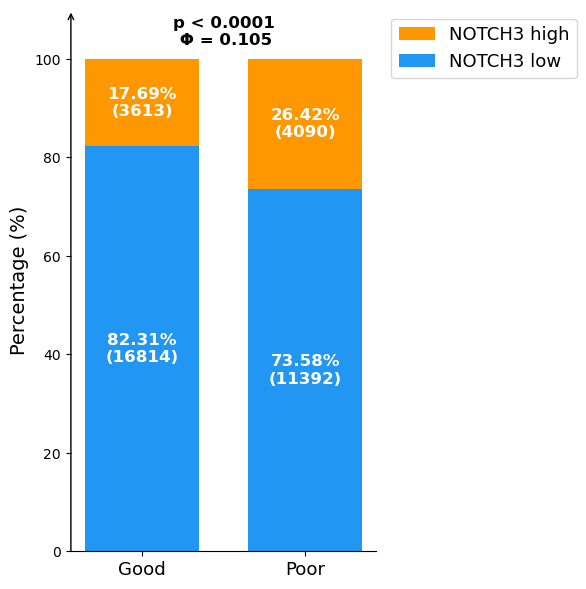

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# ===== 2x2 data for the TAGLN+ subset =====
good_high = 3613
good_low  = 16814
poor_high = 4090
poor_low  = 11392

# Calculate percentages
good_total = good_high + good_low
poor_total = poor_high + poor_low

good_high_pct = good_high / good_total * 100
good_low_pct  = good_low  / good_total * 100
poor_high_pct = poor_high / poor_total * 100
poor_low_pct  = poor_low  / poor_total * 100

# Prepare data
categories = ['Good', 'Poor']
low_pct  = [good_low_pct,  poor_low_pct]    # bottom: NOTCH3 low
high_pct = [good_high_pct, poor_high_pct]   # top: NOTCH3 high
raw_numbers = [
    [good_low, good_high],   # Good group (low first, high second, matching stack order)
    [poor_low, poor_high],   # Poor group
]

fig, ax = plt.subplots(figsize=(6, 6))

x = np.arange(len(categories))
width = 0.7

# Color scheme: blue (low) + orange (high), academic style
ax.bar(x, low_pct,  width=width, label='NOTCH3 low',  color='#2196F3')  # Material Blue
ax.bar(x, high_pct, width=width, bottom=low_pct, label='NOTCH3 high', color='#FF9800')  # Material Orange

# Annotate counts on the bars
for i in range(len(categories)):
    # low label (bottom)
    ax.text(i, low_pct[i] / 2,
            f'{low_pct[i]:.2f}%\n({raw_numbers[i][0]})',
            ha='center', va='center', color='white', fontsize=12, fontweight='bold')
    # high label (top)
    ax.text(i, low_pct[i] + high_pct[i] / 2,
            f'{high_pct[i]:.2f}%\n({raw_numbers[i][1]})',
            ha='center', va='center', color='white', fontsize=12, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=13)

ax.set_ylabel('Percentage (%)', fontsize=14)
ax.set_ylim(0, 110)
ax.set_title('p < 0.0001\n Φ = 0.105', fontsize=12, fontweight='bold', y=0.92)

# Legend order matches the stacking (high on top, low on bottom)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], bbox_to_anchor=(1.02, 1.0), loc=2, fontsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.annotate(
    '', 
    xy=(0, 1), xytext=(0, -0.005), 
    xycoords='axes fraction', 
    textcoords='axes fraction', 
    arrowprops=dict(arrowstyle='->', lw=1.), 
    clip_on=False  
)

plt.tight_layout()
plt.show()